In [1]:
import json
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

AUTOTUNE = tf.data.AUTOTUNE

IMAGES = Path("/kaggle/input/datasets/izuchukwuoruche/eyeq-512-full/eyeq_512")

SPLITS = Path("/kaggle/input/datasets/izuchukwuoruche/retina-results/manifest_split.csv")

WORK = Path("/kaggle/working")
RESULTS = WORK / "results"
FIGURES = WORK / "figures"
for d in (RESULTS, FIGURES):
    d.mkdir(exist_ok=True)

CLASSES = ["Good", "Usable", "Reject"]
N_CLASSES = 3
SEED = 42

print("TF", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TF 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
df = pd.read_csv(SPLITS)

train = df[df.split == "train"]
val = df[df.split == "val"]
test = df[df.split == "test"]

print({k: len(v) for k, v in [("train", train), ("val", val), ("test", test)]})
print(train.quality.value_counts(normalize=True).round(3).to_dict())

# same guard as last week - cheap, and it catches a wrong file
spread = df.groupby("patient_id")["split"].nunique()
assert (spread == 1).all(), "patient leakage in the loaded splits"
print("splits verified")

{'train': 10264, 'val': 2279, 'test': 16249}
{0: 0.662, 2: 0.186, 1: 0.152}
splits verified


In [3]:
def decode(path, label, size):
    """Read a PNG and resize. Returns float32 in [0, 255] - NOT normalised."""
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (size, size), method="area")
    return tf.cast(img, tf.float32), label


def augment(img, label):
    """Geometric only. See the note below - this is not the usual advice."""
    img = tf.image.random_flip_left_right(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return img, label


def make_ds(sub, size, batch=32, training=False):
    paths = np.array([str(IMAGES / f"{s}.png") for s in sub.stem])
    labels = sub.quality.values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(sub), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: decode(p, y, size), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch).prefetch(AUTOTUNE)

I0000 00:00:1789969730.169626      25 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789969730.172835      25 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


batch: (8, 224, 224, 3) <dtype: 'float32'>
range: 0.0 - 255.0048828125


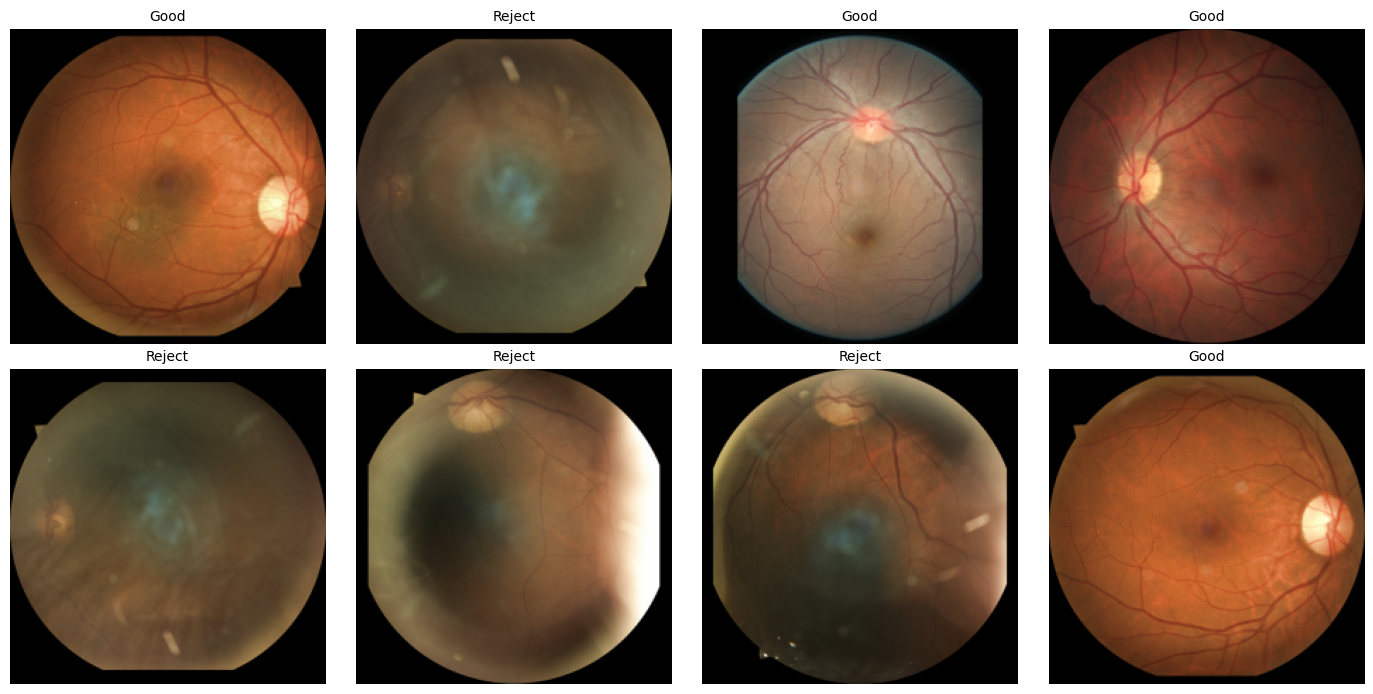

In [4]:
ds = make_ds(train.head(16), size=224, batch=8, training=True)
imgs, labs = next(iter(ds))

print("batch:", imgs.shape, imgs.dtype)
print("range:", float(tf.reduce_min(imgs)), "-", float(tf.reduce_max(imgs)))
# expect roughly 0.0 - 255.0. If it says 0.0 - 1.0 you normalised somewhere.

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, lab in zip(axes.ravel(), imgs, labs):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(CLASSES[int(lab)], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
def build_model(size, n_classes=N_CLASSES, dropout=0.3):
    """EfficientNet-B0, frozen backbone, fresh head.

    Returns (model, base) so the caller can unfreeze for phase 2.
    """
    inputs = keras.Input(shape=(size, size, 3))

    base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(size, size, 3))
    base.trainable = False

    # training=False keeps BatchNorm in inference mode permanently, using the
    # pretrained moving statistics. Without this, fine-tuning with batches of
    # 32 corrupts those statistics and accuracy collapses for no visible reason.
    x = base(inputs, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(n_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs), base

In [6]:
model, base = build_model(size=224)
n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"trainable params: {n_train:,}")
# expect ~3,800 - only the head. The 4M backbone params are frozen.

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
trainable params: 3,843


In [7]:
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

y_tr = train.quality.values
weights = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
class_weight = dict(enumerate(weights))
print(class_weight)     # roughly {0: 0.50, 1: 2.19, 2: 1.79} on the wk5 split

{0: np.float64(0.5032852799843092), 1: np.float64(2.1945691682702586), 2: np.float64(1.7940919419681873)}


In [8]:
class MacroF1(keras.callbacks.Callback):
    """Adds val_macro_f1 to logs so EarlyStopping can monitor it.

    Labels are collected once at construction. Predictions come from a single
    predict() call over the whole validation set - calling predict() per batch
    re-enters Keras 72 times an epoch and is several times slower.

    Relies on val_ds being unshuffled (make_ds with training=False), so that
    prediction order matches label order.
    """

    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds
        self.y_true = np.concatenate([y.numpy() for _, y in val_ds])

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        y_pred = self.model.predict(self.val_ds, verbose=0).argmax(axis=1)
        f1 = f1_score(self.y_true, y_pred, average="macro")
        logs["val_macro_f1"] = f1
        print(f"  - val_macro_f1: {f1:.4f}")


def callbacks_for(val_ds, ckpt, patience=5):
    return [
        MacroF1(val_ds),
        keras.callbacks.EarlyStopping(
            monitor="val_macro_f1", mode="max",
            patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_macro_f1", mode="max",
            factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(
            str(ckpt), monitor="val_macro_f1", mode="max",
            save_best_only=True, verbose=0),
    ]

In [9]:
SIZE = 224
BATCH = 32

train_ds = make_ds(train, SIZE, BATCH, training=True)
val_ds = make_ds(val, SIZE, BATCH)
test_ds = make_ds(test, SIZE, BATCH)

model, base = build_model(SIZE)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

hist1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight,
    callbacks=callbacks_for(val_ds, WORK / "phase1.keras"),
)

Epoch 1/20


2026-09-21 05:49:30.740982: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:49:30.885385: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:49:31.234287: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:49:31.377373: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:49:32.198299: E external/local_xla/xla/stream_

320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.7699 - loss: 0.6681

2026-09-21 05:50:40.478800: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:50:40.621942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:50:40.960595: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:50:41.102935: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:50:41.921299: E external/local_xla/xla/stream_

321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.7700 - loss: 0.6678

2026-09-21 05:51:06.447859: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:51:06.583586: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:51:06.898391: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:51:07.039971: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 05:51:07.831832: E external/local_xla/xla/stream_

  - val_macro_f1: 0.8148
321/321 ━━━━━━━━━━━━━━━━━━━━ 142s 351ms/step - accuracy: 0.8120 - loss: 0.5701 - val_accuracy: 0.8798 - val_loss: 0.3504 - val_macro_f1: 0.8148 - learning_rate: 0.0010
Epoch 2/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8555 - loss: 0.4558  - val_macro_f1: 0.8423
321/321 ━━━━━━━━━━━━━━━━━━━━ 43s 132ms/step - accuracy: 0.8534 - loss: 0.4565 - val_accuracy: 0.9035 - val_loss: 0.2883 - val_macro_f1: 0.8423 - learning_rate: 0.0010
Epoch 3/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8608 - loss: 0.4298  - val_macro_f1: 0.8408
321/321 ━━━━━━━━━━━━━━━━━━━━ 42s 131ms/step - accuracy: 0.8625 - loss: 0.4255 - val_accuracy: 0.9057 - val_loss: 0.2702 - val_macro_f1: 0.8408 - learning_rate: 0.0010
Epoch 4/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8755 - loss: 0.3952  - val_macro_f1: 0.8450
321/321 ━━━━━━━━━━━━━━━━━━━━ 82s 130ms/step - accuracy: 0.8724 - loss: 0.4066 - val_accuracy: 0.9013 - val_loss: 0.2942 - val_macro_f1: 0.84

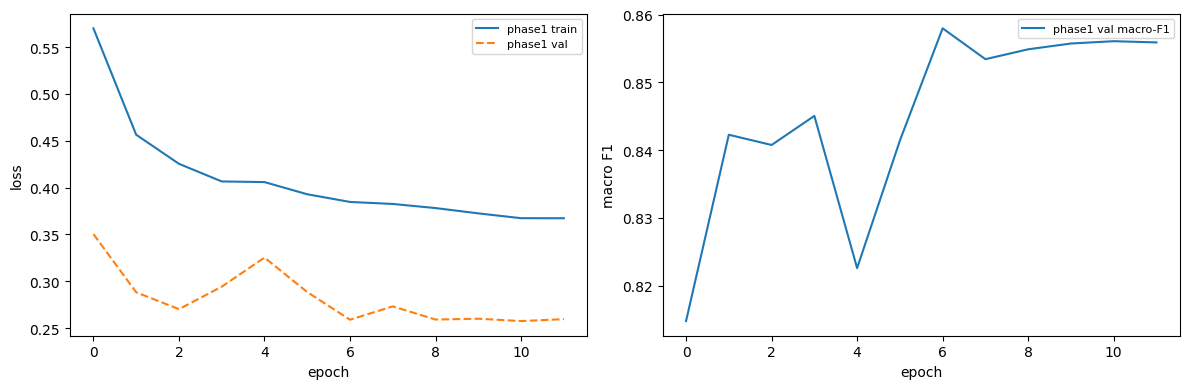

In [10]:
def plot_history(hists, path, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in hists.items():
        axes[0].plot(h.history["loss"], label=f"{name} train")
        axes[0].plot(h.history["val_loss"], "--", label=f"{name} val")
        axes[1].plot(h.history["val_macro_f1"], label=f"{name} val macro-F1")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("macro F1")
    for a in axes:
        a.legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


plot_history({"phase1": hist1}, FIGURES / "history_phase1.png")

trainable params: 3,844,191
Epoch 1/20


2026-09-21 06:01:11.738263: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:01:11.890701: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7453 - loss: 0.7102

2026-09-21 06:02:05.076874: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:02:05.223237: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:02:06.003008: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:02:06.145778: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.7455 - loss: 0.7100  - val_macro_f1: 0.8126
321/321 ━━━━━━━━━━━━━━━━━━━━ 140s 284ms/step - accuracy: 0.7829 - loss: 0.6372 - val_accuracy: 0.8881 - val_loss: 0.3114 - val_macro_f1: 0.8126 - learning_rate: 1.0000e-05
Epoch 2/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8275 - loss: 0.5301  - val_macro_f1: 0.8243
321/321 ━━━━━━━━━━━━━━━━━━━━ 44s 136ms/step - accuracy: 0.8348 - loss: 0.5043 - val_accuracy: 0.8947 - val_loss: 0.2761 - val_macro_f1: 0.8243 - learning_rate: 1.0000e-05
Epoch 3/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8516 - loss: 0.4567  - val_macro_f1: 0.8313
321/321 ━━━━━━━━━━━━━━━━━━━━ 82s 137ms/step - accuracy: 0.8551 - loss: 0.4552 - val_accuracy: 0.8969 - val_loss: 0.2659 - val_macro_f1: 0.8313 - learning_rate: 1.0000e-05
Epoch 4/20
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8624 - loss: 0.4200  - val_macro_f1: 0.8435
321/321 ━━━━━━━━━━━━━━━━━━━━ 44s 137ms/step - accura

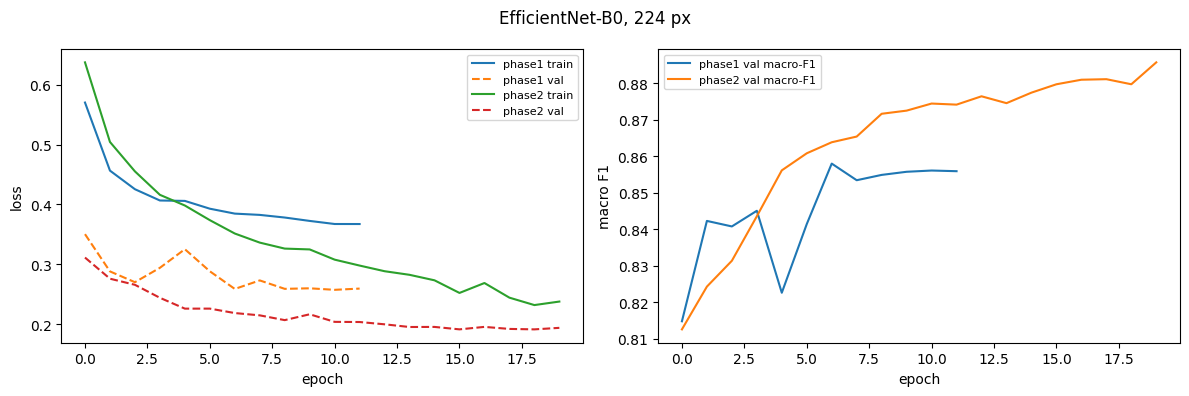

In [11]:
base.trainable = True

# the earliest blocks learn generic edge and colour features that transfer
# fine and do not need to move
FREEZE_UNTIL = 100
for layer in base.layers[:FREEZE_UNTIL]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),        # 100x lower than phase 1
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"trainable params: "
      f"{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}")

hist2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight,
    callbacks=callbacks_for(val_ds, WORK / "effnet_b0_best.keras"),
)

plot_history({"phase1": hist1, "phase2": hist2},
             FIGURES / "history_both.png", title="EfficientNet-B0, 224 px")

In [12]:
from sklearn.metrics import (accuracy_score, cohen_kappa_score,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support)


def three_class_report(y_true, y_pred):
    p, r, f1, n = precision_recall_fscore_support(
        y_true, y_pred, labels=range(3), zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
        "kappa": float(cohen_kappa_score(y_true, y_pred, weights="quadratic")),
        "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]),
                          "f1": float(f1[i]), "n": int(n[i])}
                      for i, c in enumerate(CLASSES)},
        "confusion": confusion_matrix(y_true, y_pred, labels=range(3)).tolist(),
    }


def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng, n = np.random.default_rng(seed), len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return float(metric_fn(y_true, y_pred)), float(lo), float(hi)


def plot_confusion(cm, path, title=""):
    cm = np.asarray(cm)
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(cmn, cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    if title:
        ax.set_title(title, fontsize=11)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.0%}",
                    ha="center", va="center", fontsize=9,
                    color="white" if cmn[i, j] > 0.5 else "black")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


import datetime


def record(name, params, metrics, code_version="", notes=""):
    payload = {"name": name,
               "when": datetime.datetime.now().isoformat(timespec="seconds"),
               "code_version": code_version, "params": params,
               "metrics": metrics, "notes": notes}
    (RESULTS / f"{name}.json").write_text(json.dumps(payload, indent=2))
    print(f"recorded {name}")
    return payload

507/508 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step

2026-09-21 06:20:36.812871: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:20:36.956665: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:20:37.299686: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:20:37.442748: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:20:38.251755: E external/local_xla/xla/stream_

508/508 ━━━━━━━━━━━━━━━━━━━━ 99s 195ms/step
accuracy  0.884   95% CI [0.879, 0.888]
macro F1  0.867
kappa     0.900

{
  "Good": {
    "precision": 0.9258658635468551,
    "recall": 0.9435721874631094,
    "f1": 0.9346351730589336,
    "n": 8471
  },
  "Usable": {
    "precision": 0.7945744913585648,
    "recall": 0.7968407196138657,
    "f1": 0.7957059918939643,
    "n": 4558
  },
  "Reject": {
    "precision": 0.89688013136289,
    "recall": 0.848136645962733,
    "f1": 0.8718276137270551,
    "n": 3220
  }
}


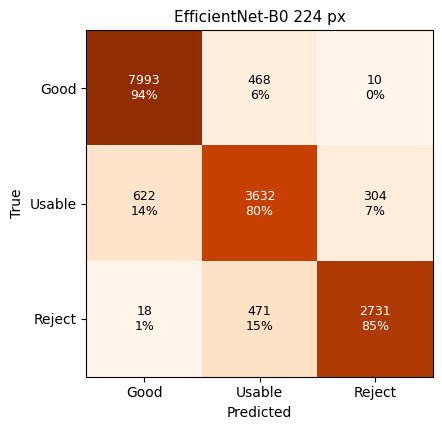

recorded w6-effnet-b0-224


{'name': 'w6-effnet-b0-224',
 'when': '2026-09-21T06:20:43',
 'code_version': 'wk6-v1',
 'params': {'backbone': 'EfficientNetB0',
  'size': 224,
  'batch': 32,
  'phase1_lr': 0.001,
  'phase2_lr': 1e-05,
  'freeze_until': 100,
  'class_weight': 'balanced',
  'augment': 'hflip + rot90 only',
  'epochs_p1': 12,
  'epochs_p2': 20},
 'metrics': {'accuracy': 0.8835005231091144,
  'macro_f1': 0.8673895928933177,
  'kappa': 0.89993613678493,
  'acc_ci': [0.8789463967013355, 0.8884269801218536],
  'per_class': {'Good': {'precision': 0.9258658635468551,
    'recall': 0.9435721874631094,
    'f1': 0.9346351730589336,
    'n': 8471},
   'Usable': {'precision': 0.7945744913585648,
    'recall': 0.7968407196138657,
    'f1': 0.7957059918939643,
    'n': 4558},
   'Reject': {'precision': 0.89688013136289,
    'recall': 0.848136645962733,
    'f1': 0.8718276137270551,
    'n': 3220}}},
 'notes': 'Two-phase transfer learning. Geometric augmentation only - photometric augmentation would destroy the exp

In [13]:
y_true = test.quality.values
y_prob = model.predict(test_ds, verbose=1)
y_pred = y_prob.argmax(axis=1)

rep = three_class_report(y_true, y_pred)
acc, lo, hi = bootstrap_ci(y_true, y_pred, accuracy_score)

print(f"accuracy  {acc:.3f}   95% CI [{lo:.3f}, {hi:.3f}]")
print(f"macro F1  {rep['macro_f1']:.3f}")
print(f"kappa     {rep['kappa']:.3f}")
print()
print(json.dumps(rep["per_class"], indent=2))

plot_confusion(rep["confusion"], FIGURES / "confusion_effnet224.png",
               title="EfficientNet-B0 224 px")

record("w6-effnet-b0-224",
       {"backbone": "EfficientNetB0", "size": SIZE, "batch": BATCH,
        "phase1_lr": 1e-3, "phase2_lr": 1e-5, "freeze_until": FREEZE_UNTIL,
        "class_weight": "balanced", "augment": "hflip + rot90 only",
        "epochs_p1": len(hist1.history["loss"]),
        "epochs_p2": len(hist2.history["loss"])},
       {**{k: rep[k] for k in ["accuracy", "macro_f1", "kappa"]},
        "acc_ci": [lo, hi], "per_class": rep["per_class"]},
       code_version="wk6-v1",
       notes="Two-phase transfer learning. Geometric augmentation only - "
             "photometric augmentation would destroy the exposure signal.")

In [14]:
cm = np.array(rep["confusion"])
print(f"Reject misread as Good: {cm[2, 0]}/{cm[2].sum()} "
      f"({cm[2, 0] / cm[2].sum():.1%})")

Reject misread as Good: 18/3220 (0.6%)


In [15]:
rows = []
for f in sorted(RESULTS.glob("*.json")):
    d = json.loads(f.read_text())
    rows.append({"model": d["name"],
                 "accuracy": d["metrics"]["accuracy"],
                 "macro_f1": d["metrics"]["macro_f1"]})

# week 5's numbers - they live in the other Dataset
rows.insert(0, {"model": "majority-class (wk5)", "accuracy": 0.521, "macro_f1": 0.228})
rows.insert(1, {"model": "classical-lgbm (wk5)", "accuracy": 0.710, "macro_f1": 0.657})

print(pd.DataFrame(rows).to_markdown(index=False, floatfmt=".3f"))

| model                |   accuracy |   macro_f1 |
|:---------------------|-----------:|-----------:|
| majority-class (wk5) |      0.521 |      0.228 |
| classical-lgbm (wk5) |      0.710 |      0.657 |
| w6-effnet-b0-224     |      0.884 |      0.867 |


In [16]:
SIZE_2, BATCH_2 = 384, 16      # larger images, smaller batch to fit memory

train_ds2 = make_ds(train, SIZE_2, BATCH_2, training=True)
val_ds2 = make_ds(val, SIZE_2, BATCH_2)
test_ds2 = make_ds(test, SIZE_2, BATCH_2)

model2, base2 = build_model(SIZE_2)
model2.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model2.fit(train_ds2, validation_data=val_ds2, epochs=20,
                class_weight=class_weight,
                callbacks=callbacks_for(val_ds2, WORK / "phase1_384.keras"))

base2.trainable = True
for layer in base2.layers[:FREEZE_UNTIL]:
    layer.trainable = False
model2.compile(optimizer=keras.optimizers.Adam(1e-5),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model2.fit(train_ds2, validation_data=val_ds2, epochs=20,
                class_weight=class_weight,
                callbacks=callbacks_for(val_ds2, WORK / "effnet_b0_384.keras"))

y_pred2 = model2.predict(test_ds2, verbose=1).argmax(axis=1)
rep2 = three_class_report(y_true, y_pred2)
acc2, lo2, hi2 = bootstrap_ci(y_true, y_pred2, accuracy_score)

print(f"224 px: {rep['accuracy']:.3f} acc, {rep['macro_f1']:.3f} macro-F1")
print(f"384 px: {rep2['accuracy']:.3f} acc, {rep2['macro_f1']:.3f} macro-F1")

record("w6-effnet-b0-384", {"size": SIZE_2, "batch": BATCH_2},
       {**{k: rep2[k] for k in ["accuracy", "macro_f1", "kappa"]},
        "acc_ci": [lo2, hi2], "per_class": rep2["per_class"]},
       code_version="wk6-v1", notes="Resolution ablation against 224 px.")

Epoch 1/20


2026-09-21 06:21:13.890234: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:21:14.037801: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:21:14.402463: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:21:14.544804: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:21:15.372501: E external/local_xla/xla/stream_

641/642 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.7735 - loss: 0.6362

2026-09-21 06:22:11.182905: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:22:11.323237: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:22:11.650010: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:22:11.792452: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:22:12.640051: E external/local_xla/xla/stream_

642/642 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.7736 - loss: 0.6361

...

2026-09-21 06:39:03.860750: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:39:04.002673: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:39:05.253686: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:39:05.395344: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 06:39:05.536889: E external/local_xla/xla/stream_

642/642 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.7920 - loss: 0.6338  - val_macro_f1: 0.8459
642/642 ━━━━━━━━━━━━━━━━━━━━ 185s 203ms/step - accuracy: 0.8180 - loss: 0.5591 - val_accuracy: 0.9092 - val_loss: 0.2608 - val_macro_f1: 0.8459 - learning_rate: 1.0000e-05
Epoch 2/20
642/642 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8523 - loss: 0.4568  - val_macro_f1: 0.8577
642/642 ━━━━━━━━━━━━━━━━━━━━ 73s 114ms/step - accuracy: 0.8488 - loss: 0.4547 - val_accuracy: 0.9153 - val_loss: 0.2358 - val_macro_f1: 0.8577 - learning_rate: 1.0000e-05
Epoch 3/20
642/642 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.8771 - loss: 0.4014  - val_macro_f1: 0.8630
642/642 ━━━━━━━━━━━━━━━━━━━━ 73s 114ms/step - accuracy: 0.8729 - loss: 0.4028 - val_accuracy: 0.9171 - val_loss: 0.2284 - val_macro_f1: 0.8630 - learning_rate: 1.0000e-05
Epoch 4/20
642/642 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8747 - loss: 0.3687  - val_macro_f1: 0.8815
642/642 ━━━━━━━━━━━━━━━━━━━━ 76s 118ms/step - accura

2026-09-21 07:00:10.309017: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 07:00:10.449900: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 07:00:10.781306: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 07:00:10.923916: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-21 07:00:11.066535: E external/local_xla/xla/stream_

1016/1016 ━━━━━━━━━━━━━━━━━━━━ 70s 69ms/step
224 px: 0.884 acc, 0.867 macro-F1
384 px: 0.884 acc, 0.866 macro-F1
recorded w6-effnet-b0-384


{'name': 'w6-effnet-b0-384',
 'when': '2026-09-21T07:00:18',
 'code_version': 'wk6-v1',
 'params': {'size': 384, 'batch': 16},
 'metrics': {'accuracy': 0.883869776601637,
  'macro_f1': 0.8664915196238755,
  'kappa': 0.9006073940329844,
  'acc_ci': [0.8790679426426241, 0.8890408640531725],
  'per_class': {'Good': {'precision': 0.930316426244765,
    'recall': 0.9440443867312006,
    'f1': 0.9371301341770668,
    'n': 8471},
   'Usable': {'precision': 0.8028673835125448,
    'recall': 0.7863097849934182,
    'f1': 0.794502327643538,
    'n': 4558},
   'Reject': {'precision': 0.8720602069614299,
    'recall': 0.863664596273292,
    'f1': 0.867842097051022,
    'n': 3220}}},
 'notes': 'Resolution ablation against 224 px.'}

In [17]:
model.save(WORK / "effnet_b0_best.keras")
size_mb = os.path.getsize(WORK / "effnet_b0_best.keras") / 1e6
print(f"model: {size_mb:.1f} MB")

# drop intermediates you do not want shipped
for junk in ["phase1.keras", "phase1_384.keras", ".virtual_documents"]:
    p = WORK / junk
    if p.is_dir():
        shutil.rmtree(p, ignore_errors=True)
    elif p.exists():
        p.unlink()

print(sorted(p.name for p in WORK.iterdir()))
print(sorted(p.name for p in RESULTS.iterdir()))
print(sorted(p.name for p in FIGURES.iterdir()))

model: 47.9 MB
['__notebook__.ipynb', 'effnet_b0_384.keras', 'effnet_b0_best.keras', 'figures', 'results']
['w6-effnet-b0-224.json', 'w6-effnet-b0-384.json']
['confusion_effnet224.png', 'history_both.png', 'history_phase1.png']
